# Análisis del comportamiento de una aplicación bajo diferentes escenarios de despliegue

**Curso:** Principios y Prácticas de Desarrollo de Software Orientado a Objetos — Prof. Gabriel Rodrigo Pedraza Ferreira

**Integrantes:**
- David Esteban Suarez Lozano · 2221909
- Thomas Alejandro Perez Rojas · 2221906
- Jesus David Santodomingo Carrascal · 2221922

**Repositorio:** https://github.com/Tapr16/Proyecto-Final-Principios · **Video de la demostración:** [`docs/video/Video-Proyecto-Final.mp4`](https://github.com/Tapr16/Proyecto-Final-Principios/blob/main/docs/video/Video-Proyecto-Final.mp4)

**Abrir en Colab:** https://colab.research.google.com/github/Tapr16/Proyecto-Final-Principios/blob/main/notebook/analisis.ipynb

## 1. Introducción y objetivos

Una misma API REST se desplegó de **10 formas** y se sometió a la misma carga con JMeter para medir cómo cambian el
**throughput**, el **tiempo de respuesta** y la **tasa de error**:

- **Docker Compose** en una sola máquina (línea base).
- **Kubernetes (K3s)** con **1, 2 y 3 nodos** y **1, 2 y 3 réplicas** de la API (9 combinaciones).

Cada escenario se probó con **10, 50, 100 y 200 usuarios concurrentes** y **3 repeticiones** por nivel: **120 corridas** en total.

**Objetivos:**
- Medir el costo (overhead) de la orquestación con Kubernetes frente a Docker Compose sobre el mismo hardware.
- Evaluar el escalado horizontal: ¿crece el throughput al agregar réplicas? ¿y al agregar nodos?
- Identificar los cuellos de botella con métricas internas (Prometheus) y no solo con las de JMeter.

## 2. Descripción de la aplicación

**Dominio:** tienda online. API REST en **FastAPI** (Python 3.12, 1 worker de Uvicorn por contenedor) con **PostgreSQL 16**
(SQLAlchemy asíncrono + asyncpg, pool de 10 + 5 conexiones por réplica).

| Tabla | Registros | Índices |
|---|---|---|
| productos | 100.000 | PK, `categoria` |
| clientes | 20.000 | PK |
| pedidos | 200.000 | PK, `cliente_id` |
| items_pedido | 599.346 | PK, `pedido_id`, `producto_id` |

Los datos se generan con Faker y **semilla fija** (`app/seed.py`), así que son idénticos en todos los escenarios, y la BD
se **resetea antes de cada escenario** (los `POST` hacen crecer la tabla de pedidos).

| Método | Ruta | Tipo de carga | Peso |
|---|---|---|---|
| GET | `/productos/{id}` | lectura por clave primaria | 50 % |
| GET | `/productos?categoria=X&page=N` | lectura paginada con filtro | 25 % |
| GET | `/productos/buscar?q=texto` | `ILIKE` en nombre y descripción + conteo (recorre toda la tabla) | 10 % |
| POST | `/pedidos` | escritura transaccional (pedido + 2 items) | 10 % |
| GET | `/reportes/ventas-por-categoria` | `JOIN` + `GROUP BY` sobre ~600K items | 5 % |

```
clientes 1───* pedidos 1───* items_pedido *───1 productos
```

## 3. Infraestructura

4 VMs en **Google Cloud** `n2d-standard-2` (2 vCPU AMD EPYC, 8 GB, **no burstable**; equivalente al `Standard_D2as_v5`
de la guía), Ubuntu 24.04, región `us-central1` (zona `c`), en la misma red privada `10.0.1.0/24`:

| VM | IP privada | Rol |
|---|---|---|
| nodo1 | 10.0.1.10 | Fase 1: Docker Compose · Fases K8s: servidor K3s + PostgreSQL + Prometheus/Grafana |
| nodo2 | 10.0.1.11 | agente K3s (desde la fase de 2 nodos) |
| nodo3 | 10.0.1.12 | agente K3s (fase de 3 nodos) |
| vm-jmeter | 10.0.1.20 | JMeter 5.6.3 (máquina distinta a la de la aplicación) |

```
 ┌──────────────┐  HTTP (red privada)  ┌──────────────────────────────────────────────┐
 │  vm-jmeter   │ ───────────────────► │ nodo1 :8000 (Docker) / :30080 (NodePort K8s) │
 │  JMeter CLI  │                      │ nodo2, nodo3 (agentes K3s)                   │
 └──────────────┘                      └──────────────────────────────────────────────┘
```

_Se intentó primero con Azure for Students, pero la cuota de la cuenta (6 vCPUs y 0 para la familia DASv5) no alcanzaba y
Azure rechazó el aumento; por eso se usó la prueba gratuita de Google Cloud._

## 4. Configuración de despliegue por escenario

| Recurso | Docker Compose | Kubernetes |
|---|---|---|
| API | `cpus: 1.0`, `mem_limit: 512m` | `limits: cpu 1, 512Mi` · `requests: cpu 250m` |
| PostgreSQL | `cpus: 1.0`, `mem_limit: 2g` | `limits: cpu 1, 2Gi` · `requests: cpu 500m`, fijo en nodo1 (`nodeSelector rol=db`) |
| Pool de conexiones | 10 + 5 overflow | 10 + 5 overflow por réplica (máx. 45 con 3 réplicas) |
| Entrada | puerto 8000 de nodo1 | NodePort 30080 de nodo1 (kube-proxy reparte a las réplicas) |
| Reparto de réplicas | — | `topologySpreadConstraints` (maxSkew 1, `ScheduleAnyway`) |
| Sondas | — | readiness HTTP `/health` (timeout 30 s, 8 fallos) · liveness TCP (ver sección 8.2) |

Los **límites** son iguales en Docker y en Kubernetes. Los `requests` de CPU son menores para que las 3 réplicas quepan en un
nodo de 2 vCPU junto a PostgreSQL y el monitoreo.

**Dónde quedó cada réplica en cada escenario** (capturas de `kubectl get pods -o wide` guardadas antes de medir):

In [1]:
import os, glob, re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

REPO_URL = "https://github.com/Tapr16/Proyecto-Final-Principios.git"
try:
    import google.colab  # noqa: F401
    EN_COLAB = True
except ImportError:
    EN_COLAB = False
if EN_COLAB and not Path("proyecto-final").exists():
    os.system(f"git clone -q {REPO_URL} proyecto-final")

RAIZ = Path(os.environ.get("PF_RAIZ", "proyecto-final" if EN_COLAB else ".."))
RESULTS = RAIZ / "results"
CAPTURAS = RAIZ / "docs" / "capturas"
DESCARTADOS = RAIZ / "results_descartados"
print("Resultados en:", RESULTS.resolve())

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
RAMP_MS = 30_000
ORDEN = ["docker"] + [f"k8s-{n}n-{r}r" for n in (1, 2, 3) for r in (1, 2, 3)]
NODOS = ["nodo1", "nodo2", "nodo3"]

filas = []
for f in sorted(RESULTS.glob("k8s-*/pods.txt")):
    reparto, pg = {}, "?"
    for linea in f.read_text().splitlines():
        nodo = next((t for t in linea.split() if re.fullmatch(r"nodo\d", t)), None)
        if linea.startswith("api-") and nodo:
            reparto[nodo] = reparto.get(nodo, 0) + 1
        elif linea.startswith("postgres-") and nodo:
            pg = nodo
    filas.append({"escenario": f.parent.name, **{n: reparto.get(n, 0) for n in NODOS}, "PostgreSQL en": pg})
pd.DataFrame(filas).set_index("escenario").rename(columns=lambda c: f"réplicas en {c}" if c in NODOS else c)

Resultados en: C:\Users\Thomas\Documents\proyecto-final\results


,réplicas en nodo1,réplicas en nodo2,réplicas en nodo3,PostgreSQL en
escenario,,,,
k8s-1n-1r,1,0,0,nodo1
k8s-1n-2r,2,0,0,nodo1
k8s-1n-3r,3,0,0,nodo1
k8s-2n-1r,1,0,0,nodo1
k8s-2n-2r,1,1,0,nodo1
k8s-2n-3r,1,2,0,nodo1
k8s-3n-1r,0,1,0,nodo1
k8s-3n-2r,0,1,1,nodo1
k8s-3n-3r,1,1,1,nodo1


In [2]:
# Ejemplo de captura completa: 3 nodos y 3 réplicas
print((RESULTS / "k8s-3n-3r" / "pods.txt").read_text())

NAME    STATUS   ROLES           AGE    VERSION        INTERNAL-IP   EXTERNAL-IP   OS-IMAGE             KERNEL-VERSION           CONTAINER-RUNTIME
nodo1   Ready    control-plane   18h    v1.36.5+k3s1   10.0.1.10     <none>        Ubuntu 24.04.5 LTS   7.0.0-1014-gcp (amd64)   containerd://2.3.4-k3s1.36
nodo2   Ready    <none>          4h8m   v1.36.5+k3s1   10.0.1.11     <none>        Ubuntu 24.04.5 LTS   7.0.0-1014-gcp (amd64)   containerd://2.3.4-k3s1.36
nodo3   Ready    <none>          96m    v1.36.5+k3s1   10.0.1.12     <none>        Ubuntu 24.04.5 LTS   7.0.0-1014-gcp (amd64)   containerd://2.3.4-k3s1.36

NAME                   READY   STATUS      RESTARTS       AGE   IP           NODE    NOMINATED NODE   READINESS GATES
api-6f4d7dbbdb-9c8q4   1/1     Running     0              37s   10.42.0.55   nodo1   <none>           <none>
api-6f4d7dbbdb-tcd4m   1/1     Running     0              47m   10.42.2.4    nodo3   <none>           <none>
api-6f4d7dbbdb-tscs4   1/1     Running     0    

## 5. Configuración de la monitorización

- **Docker (Fase 1):** Prometheus + Grafana + cAdvisor + node-exporter (`docker-compose.monitoring.yml`).
  Docker 29 usa por defecto el almacén de imágenes de containerd, que cAdvisor no reconoce: se configuró el almacenamiento
  clásico `overlay2` (`/etc/docker/daemon.json`) para tener métricas por contenedor.
- **Kubernetes:** `kube-prometheus-stack` (Helm) con Alertmanager desactivado, Prometheus y Grafana fijos en nodo1,
  node-exporter en todos los nodos y un `ServiceMonitor` para el `/metrics` de la API
  (`prometheus-fastapi-instrumentator`). Se instaló una vez y se dejó activo en todas las fases de K8s.
- Las métricas de cada corrida se exportaron a CSV (`scripts/exportar_prometheus.py`) con los tiempos de `results/runs.csv`.

Capturas tomadas durante la carga con 200 usuarios:

Docker: CPU de la API (verde) vs. PostgreSQL (azul)


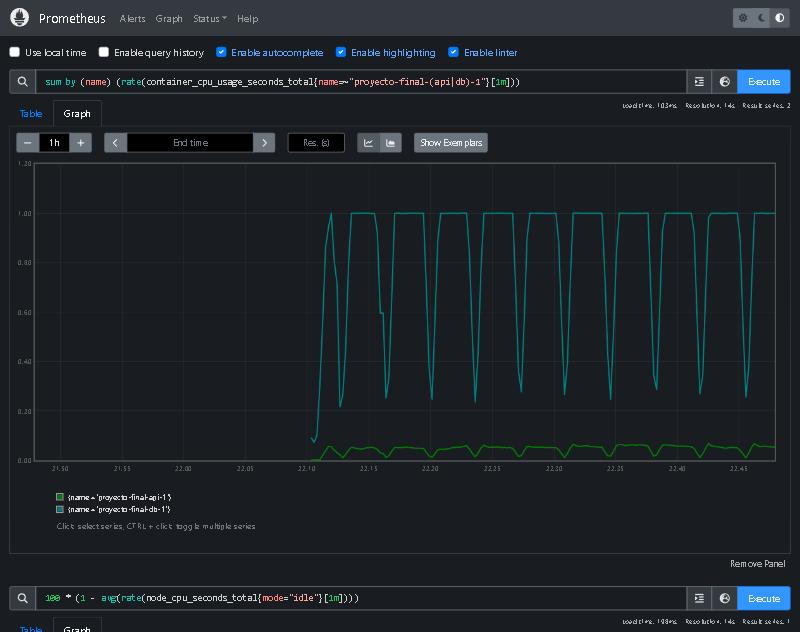

K8s 1 nodo, 3 réplicas: CPU por pod (Grafana)


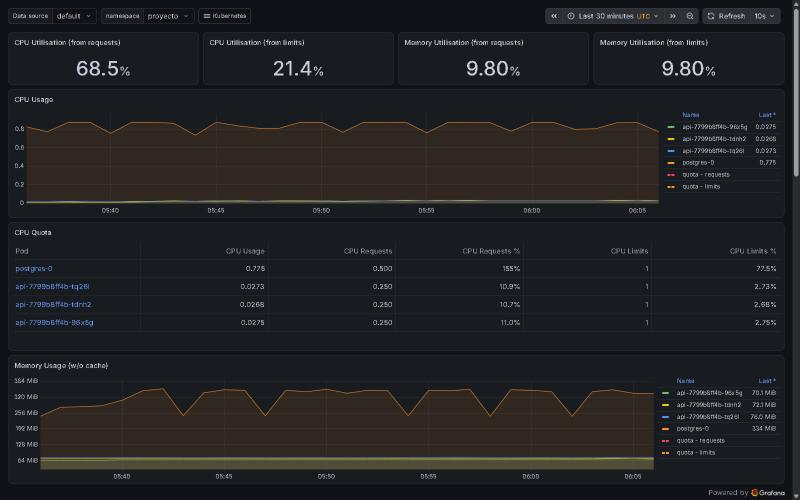

K8s 3 nodos, 3 réplicas: % de CPU por nodo (Prometheus)


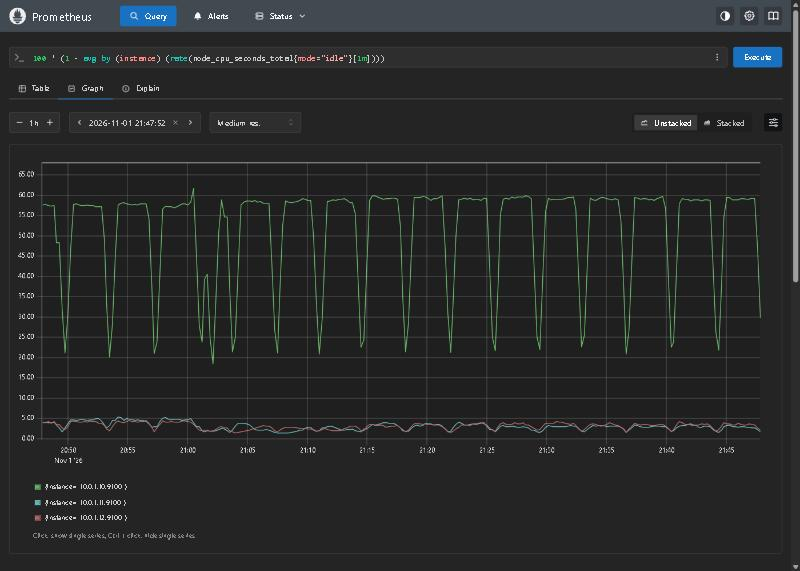

In [3]:
for archivo, titulo in [
    ("fase1-docker-cpu-api-vs-db.jpg", "Docker: CPU de la API (verde) vs. PostgreSQL (azul)"),
    ("fase2-k8s-1n-3r-grafana.jpg", "K8s 1 nodo, 3 réplicas: CPU por pod (Grafana)"),
    ("fase4-k8s-3n-3r-cpu-por-nodo.jpg", "K8s 3 nodos, 3 réplicas: % de CPU por nodo (Prometheus)"),
]:
    print(titulo)
    display(Image(filename=str(CAPTURAS / archivo), width=850))

## 6. Metodología JMeter

- **JMeter 5.6.3** en modo CLI desde `vm-jmeter`, en la misma red privada que la aplicación (`jmeter/plan.jmx`).
- Mezcla de peticiones con Throughput Controllers (50 / 25 / 10 / 10 / 5 %), datos de `jmeter/ids.csv`
  (IDs válidos, categorías y términos de búsqueda) y aserción de código 200/201.
- **Niveles de carga:** 10, 50, 100 y 200 usuarios · **3 repeticiones** · 180 s por corrida con 30 s de ramp-up.
- **Calentamiento** de 60 s descartado al inicio de cada escenario y **30 s de enfriamiento** entre corridas.
- Al calcular métricas **se descartan los primeros 30 s** (ramp-up) de cada corrida.
- **Reglas de rigor:** BD reseteada (Job `seed`) antes de cada escenario, pods `Ready` antes de medir, CPU de
  `vm-jmeter` registrada en cada corrida (`vmstat`) para descartar que el generador sea el cuello de botella.
- Las fases de Kubernetes se automatizaron con `jmeter/orquestar_fase.sh`: por cada número de réplicas resetea la BD,
  escala la API, guarda la captura de pods y lanza `jmeter/run_scenario.sh`.
- Antes de medir Kubernetes se corrigieron las sondas (sección 8.2): las corridas con las sondas por defecto se
  descartaron y se guardan en `results_descartados/` como evidencia.

## 7. Resultados

### 7.1 Carga de datos

In [4]:
filas, filas_ep = [], []
for f in sorted(RESULTS.glob("*/u*_r*.jtl")):
    esc = f.parent.name
    u, r = map(int, re.findall(r"u(\d+)_r(\d+)\.jtl$", f.name)[0])
    df = pd.read_csv(f, low_memory=False)
    df["success"] = df["success"].astype(str).str.lower() == "true"
    df = df[df.timeStamp >= df.timeStamp.min() + RAMP_MS]      # descartar ramp-up
    dur = (df.timeStamp.max() - df.timeStamp.min()) / 1000
    m = re.match(r"k8s-(\d)n-(\d)r", esc)
    base = {"escenario": esc, "plataforma": "Docker" if esc == "docker" else "K8s",
            "nodos": int(m.group(1)) if m else 1, "replicas": int(m.group(2)) if m else 1,
            "usuarios": u, "rep": r}
    filas.append({**base, "peticiones": len(df), "rt_medio_ms": df.elapsed.mean(),
                  "rt_p95_ms": df.elapsed.quantile(0.95), "throughput_rps": df.success.sum() / dur,
                  "error_pct": 100 * (1 - df.success.mean())})
    for label, g in df.groupby("label"):
        filas_ep.append({**base, "endpoint": label, "rt_medio_ms": g.elapsed.mean(),
                         "error_pct": 100 * (1 - g.success.mean()),
                         "codigos_error": g.loc[~g.success, "responseCode"].astype(str).value_counts().to_dict()})

res = pd.DataFrame(filas)
res_ep = pd.DataFrame(filas_ep)
assert len(res), f"No se encontraron .jtl en {RESULTS}"
print(f"{len(res)} corridas cargadas · {res.peticiones.sum():,} peticiones medidas")
res.groupby("escenario").size().reindex([e for e in ORDEN if e in set(res.escenario)]).to_frame("corridas").T

120 corridas cargadas · 329,184 peticiones medidas


escenario,docker,k8s-1n-1r,k8s-1n-2r,k8s-1n-3r,k8s-2n-1r,k8s-2n-2r,k8s-2n-3r,k8s-3n-1r,k8s-3n-2r,k8s-3n-3r
corridas,12,12,12,12,12,12,12,12,12,12


### 7.2 Tabla resumen (media ± desviación estándar de las 3 repeticiones)

In [5]:
claves = ["escenario", "plataforma", "nodos", "replicas", "usuarios"]
agg = res.groupby(claves).agg(
    tps=("throughput_rps", "mean"), tps_std=("throughput_rps", "std"),
    rt=("rt_medio_ms", "mean"), rt_std=("rt_medio_ms", "std"),
    p95=("rt_p95_ms", "mean"), p95_std=("rt_p95_ms", "std"),
    err=("error_pct", "mean"), err_std=("error_pct", "std"),
).reset_index().fillna({"tps_std": 0, "rt_std": 0, "p95_std": 0, "err_std": 0})
agg["escenario"] = pd.Categorical(agg.escenario, [e for e in ORDEN if e in set(agg.escenario)], ordered=True)
agg = agg.sort_values(["escenario", "usuarios"])
CARGA_MAX = agg.usuarios.max()

tabla = agg.copy()
for c in ["tps", "rt", "p95", "err"]:
    tabla[c] = tabla[c].round(1).astype(str) + " ± " + tabla[c + "_std"].round(1).astype(str)
tabla[["escenario", "usuarios", "tps", "rt", "p95", "err"]].rename(columns={
    "tps": "throughput (req/s)", "rt": "t. medio (ms)", "p95": "p95 (ms)", "err": "error (%)"}).reset_index(drop=True)

,escenario,usuarios,throughput (req/s),t. medio (ms),p95 (ms),error (%)
0,docker,10,14.4 ± 0.2,692.8 ± 7.3,4783.0 ± 15.8,0.0 ± 0.0
1,docker,50,14.7 ± 0.1,3376.9 ± 13.3,9073.3 ± 57.9,0.4 ± 0.1
2,docker,100,14.7 ± 0.2,6760.4 ± 112.2,12380.6 ± 275.9,0.6 ± 0.3
3,docker,200,14.8 ± 0.1,13668.0 ± 52.8,19466.2 ± 46.0,0.4 ± 0.2
4,k8s-1n-1r,10,13.9 ± 0.1,717.1 ± 4.6,4956.9 ± 82.3,0.0 ± 0.0
5,k8s-1n-1r,50,14.4 ± 0.4,3449.5 ± 84.0,9321.3 ± 74.1,0.5 ± 0.2
6,k8s-1n-1r,100,14.5 ± 0.1,6880.3 ± 105.3,12703.2 ± 100.7,0.4 ± 0.3
7,k8s-1n-1r,200,14.5 ± 0.1,13824.0 ± 51.9,20102.5 ± 156.4,0.9 ± 0.0
8,k8s-1n-2r,10,13.4 ± 0.5,746.5 ± 28.1,5126.8 ± 151.4,0.0 ± 0.0
9,k8s-1n-2r,50,20.0 ± 0.2,2323.3 ± 19.9,12118.6 ± 233.7,6.3 ± 0.1


### 7.3 Throughput y tiempo de respuesta vs. usuarios (una figura por número de nodos)

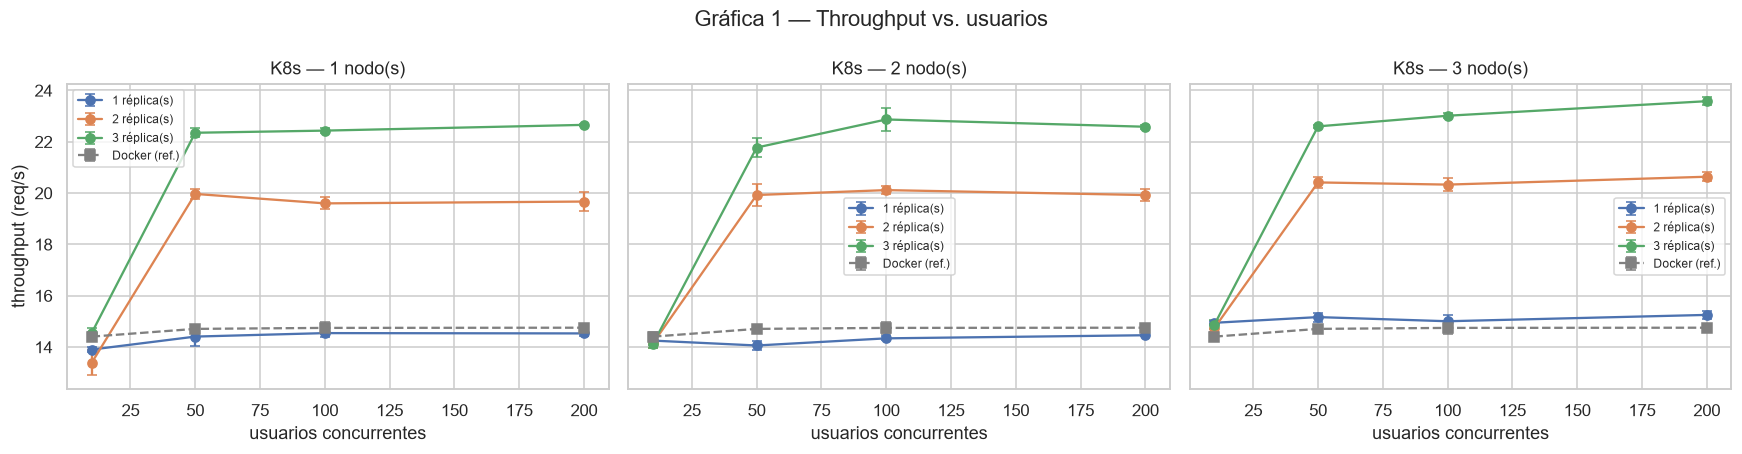

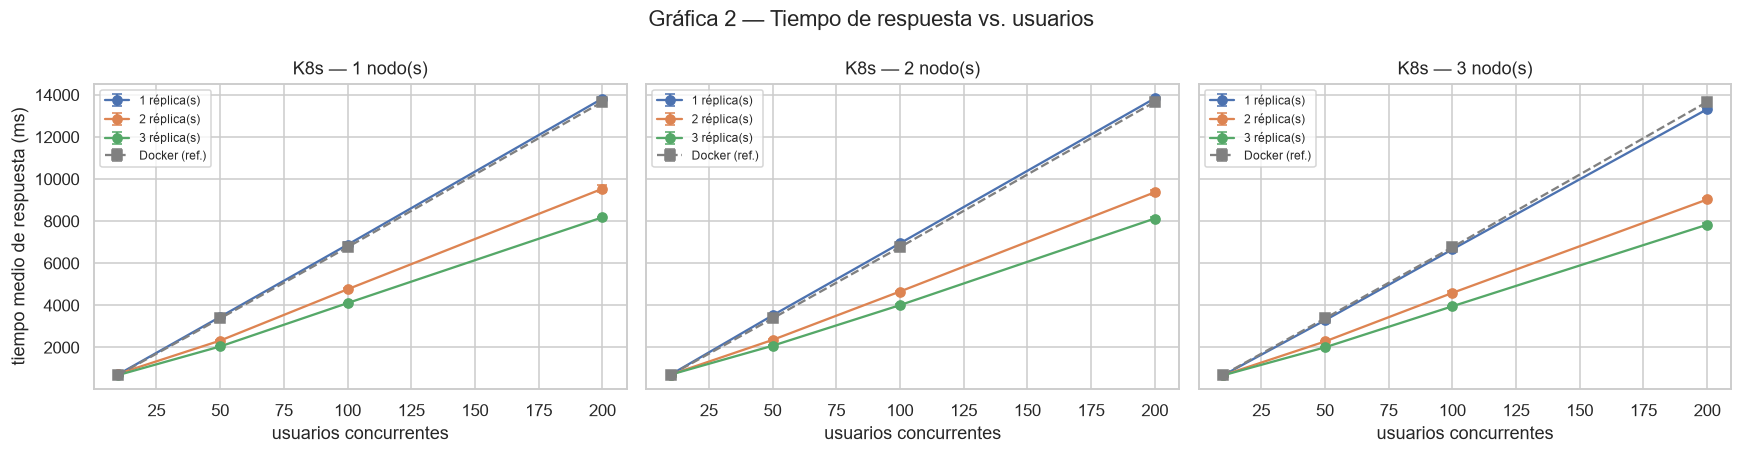

In [6]:
def por_nodos(col, std, ylabel, titulo):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
    docker = agg[agg.escenario == "docker"]
    for ax, n in zip(axes, (1, 2, 3)):
        sub = agg[(agg.plataforma == "K8s") & (agg.nodos == n)]
        for r, g in sub.groupby("replicas"):
            ax.errorbar(g.usuarios, g[col], yerr=g[std], marker="o", capsize=3, label=f"{r} réplica(s)")
        ax.errorbar(docker.usuarios, docker[col], yerr=docker[std], marker="s", ls="--",
                    color="gray", capsize=3, label="Docker (ref.)")
        ax.set_title(f"K8s — {n} nodo(s)"); ax.set_xlabel("usuarios concurrentes"); ax.legend(fontsize=8)
    axes[0].set_ylabel(ylabel)
    fig.suptitle(titulo); fig.tight_layout(); plt.show()

por_nodos("tps", "tps_std", "throughput (req/s)", "Gráfica 1 — Throughput vs. usuarios")
por_nodos("rt", "rt_std", "tiempo medio de respuesta (ms)", "Gráfica 2 — Tiempo de respuesta vs. usuarios")

### 7.4 Heatmap nodos × réplicas (throughput con la carga máxima)

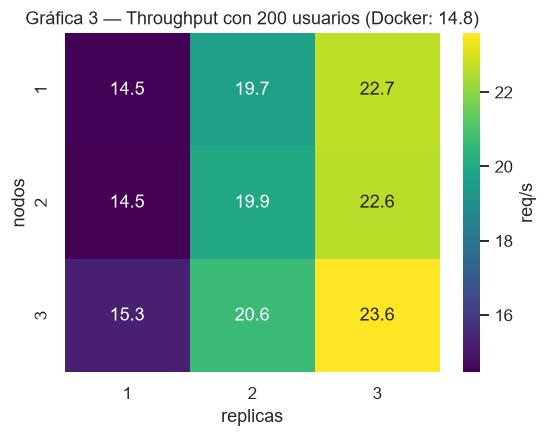

In [7]:
k8s_max = agg[(agg.plataforma == "K8s") & (agg.usuarios == CARGA_MAX)]
hm = k8s_max.pivot_table(index="nodos", columns="replicas", values="tps", observed=True)
plt.figure(figsize=(5.5, 4))
sns.heatmap(hm, annot=True, fmt=".1f", cmap="viridis", cbar_kws={"label": "req/s"})
plt.title(f"Gráfica 3 — Throughput con {CARGA_MAX} usuarios (Docker: "
          f"{agg[(agg.escenario == 'docker') & (agg.usuarios == CARGA_MAX)].tps.iloc[0]:.1f})")
plt.show()

### 7.5 Speedup al aumentar réplicas

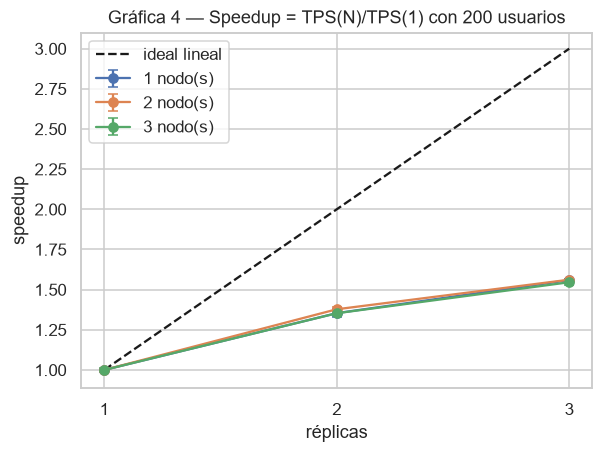

replicas,1,2,3
nodos,,,
1,1.0,1.35,1.56
2,1.0,1.38,1.56
3,1.0,1.35,1.55


In [8]:
fig, ax = plt.subplots(figsize=(6, 4.2))
for n, g in k8s_max.groupby("nodos"):
    base = g[g.replicas == 1]
    b, b_std = base.tps.iloc[0], base.tps_std.iloc[0]
    g = g.sort_values("replicas")
    s = g.tps / b
    s_std = s * np.sqrt((g.tps_std / g.tps) ** 2 + (b_std / b) ** 2)   # propagación del error del cociente
    ax.errorbar(g.replicas, s, yerr=s_std, marker="o", capsize=3, label=f"{n} nodo(s)")
ax.plot([1, 2, 3], [1, 2, 3], "k--", label="ideal lineal")
ax.set_xticks([1, 2, 3]); ax.set_xlabel("réplicas"); ax.set_ylabel("speedup")
ax.set_title(f"Gráfica 4 — Speedup = TPS(N)/TPS(1) con {CARGA_MAX} usuarios"); ax.legend(); plt.show()
k8s_max.assign(speedup=k8s_max.groupby("nodos").tps.transform(lambda t: t / t.iloc[0])).pivot_table(
    index="nodos", columns="replicas", values="speedup", observed=True).round(2)

### 7.6 Docker vs. K8s con 1 nodo y 1 réplica (costo de la orquestación)

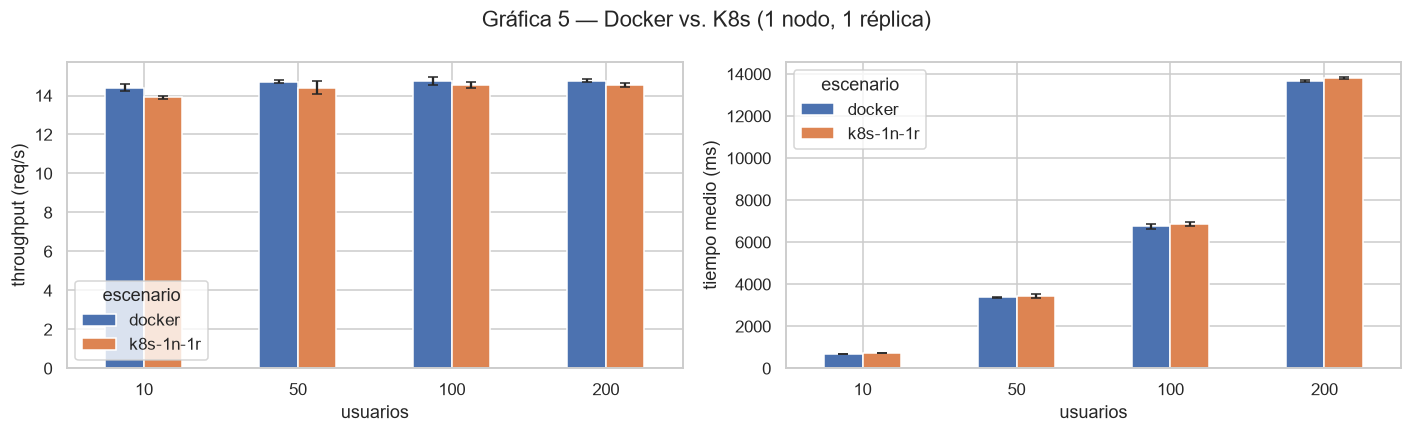

Diferencia de throughput de K8s respecto a Docker (%):
usuarios
10    -3.5
50    -2.0
100   -1.4
200   -1.5


In [9]:
comp = agg[agg.escenario.isin(["docker", "k8s-1n-1r"])]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (col, std, lab) in zip(axes, [("tps", "tps_std", "throughput (req/s)"), ("rt", "rt_std", "tiempo medio (ms)")]):
    piv = comp.pivot_table(index="usuarios", columns="escenario", values=col, observed=True)
    err = comp.pivot_table(index="usuarios", columns="escenario", values=std, observed=True)
    piv.plot.bar(yerr=err, ax=ax, capsize=3, rot=0); ax.set_ylabel(lab)
fig.suptitle("Gráfica 5 — Docker vs. K8s (1 nodo, 1 réplica)"); fig.tight_layout(); plt.show()

t = comp.pivot_table(index="usuarios", columns="escenario", values="tps", observed=True)
print("Diferencia de throughput de K8s respecto a Docker (%):")
print((100 * (t["k8s-1n-1r"] - t["docker"]) / t["docker"]).round(1).to_string())

### 7.7 Mismas réplicas, distinto número de nodos (escalado horizontal)

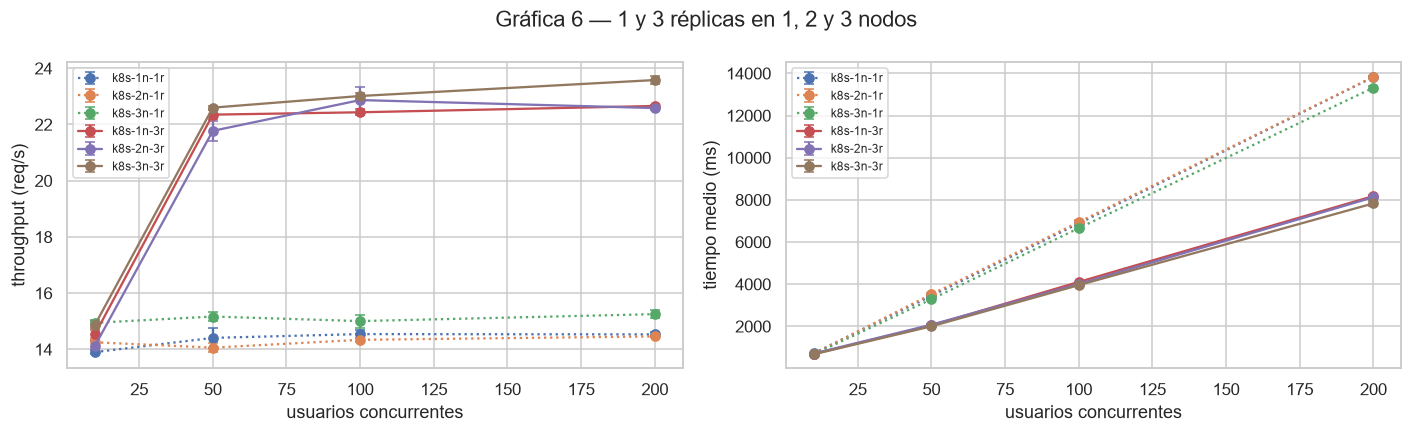

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for r, estilo in [(1, ":"), (3, "-")]:
    for esc, g in agg[agg.escenario.isin([f"k8s-{n}n-{r}r" for n in (1, 2, 3)])].groupby("escenario", observed=True):
        axes[0].errorbar(g.usuarios, g.tps, yerr=g.tps_std, marker="o", ls=estilo, capsize=3, label=esc)
        axes[1].errorbar(g.usuarios, g.rt, yerr=g.rt_std, marker="o", ls=estilo, capsize=3, label=esc)
axes[0].set_ylabel("throughput (req/s)"); axes[1].set_ylabel("tiempo medio (ms)")
for ax in axes:
    ax.set_xlabel("usuarios concurrentes"); ax.legend(fontsize=8)
fig.suptitle("Gráfica 6 — 1 y 3 réplicas en 1, 2 y 3 nodos"); fig.tight_layout(); plt.show()

### 7.8 Tasa de error por escenario y carga

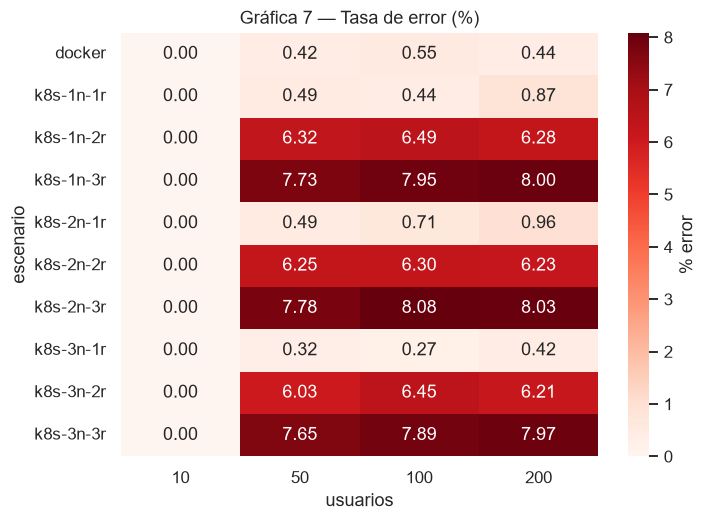

In [11]:
err = agg.pivot_table(index="escenario", columns="usuarios", values="err", observed=True)
plt.figure(figsize=(7, 5))
sns.heatmap(err, annot=True, fmt=".2f", cmap="Reds", cbar_kws={"label": "% error"})
plt.title("Gráfica 7 — Tasa de error (%)"); plt.show()

### 7.9 ¿De qué están hechos los errores con 2 y 3 réplicas?

Con 2 y 3 réplicas aparece un 6-8 % de errores que no existe con 1 réplica. Se separan por endpoint:

In [12]:
ep_err = (res_ep[res_ep.usuarios >= 100].groupby(["replicas", "endpoint"]).error_pct.mean()
          .unstack("replicas").round(1))
ep_err.columns = [f"{c} réplica(s)" for c in ep_err.columns]
print("% de peticiones fallidas por endpoint (media de 100 y 200 usuarios; 1 réplica incluye Docker):")
display(ep_err)

codigos = {}
for d in res_ep[(res_ep.replicas == 3) & (res_ep.usuarios >= 100)].itertuples():
    for k, v in d.codigos_error.items():
        k = k.replace("Non HTTP response code: ", "").split(".")[-1]
        codigos[(d.endpoint, k)] = codigos.get((d.endpoint, k), 0) + v
tot = sum(codigos.values())
print("Composición de los errores con 3 réplicas (100-200 usuarios):")
(pd.Series(codigos).sort_values(ascending=False) / tot * 100).round(1).head(6).to_frame("% de los errores")

% de peticiones fallidas por endpoint (media de 100 y 200 usuarios; 1 réplica incluye Docker):


,1 réplica(s),2 réplica(s),3 réplica(s)
endpoint,,,
GET /productos/buscar,0.2,0.0,0.6
GET /productos/{id},0.3,3.9,5.2
GET /productos?categoria,0.2,3.8,4.5
GET /reportes/ventas-por-categoria,6.8,68.8,83.9
POST /pedidos,0.0,0.0,0.0


Composición de los errores con 3 réplicas (100-200 usuarios):


,,% de los errores
GET /reportes/ventas-por-categoria,500,49.8
GET /productos/{id},SocketException,32.4
GET /productos?categoria,SocketException,14.1
GET /reportes/ventas-por-categoria,SocketTimeoutException,2.8
GET /productos/buscar,SocketTimeoutException,0.7
GET /productos/{id},NoHttpResponseException,0.1


**Lectura:** con 2-3 réplicas **falla la mayoría de los reportes** (`500`). El log de PostgreSQL muestra
`could not resize shared memory segment … No space left on device`: el reporte usa *parallel workers*, que reservan
memoria en `/dev/shm` (64 MB por defecto, igual en Docker y en K8s). Con 1 réplica hay como máximo 15 conexiones y pocos
reportes simultáneos; con 3 réplicas hay hasta 45 y la memoria compartida se agota. El resto son `SocketException`
(conexión reiniciada) en lecturas simples; la causa más probable es que Uvicorn cierra las conexiones *keep-alive*
inactivas, que con más réplicas pasan más tiempo sin uso (no se confirmó).

### 7.10 ¿Qué endpoint se degrada más?

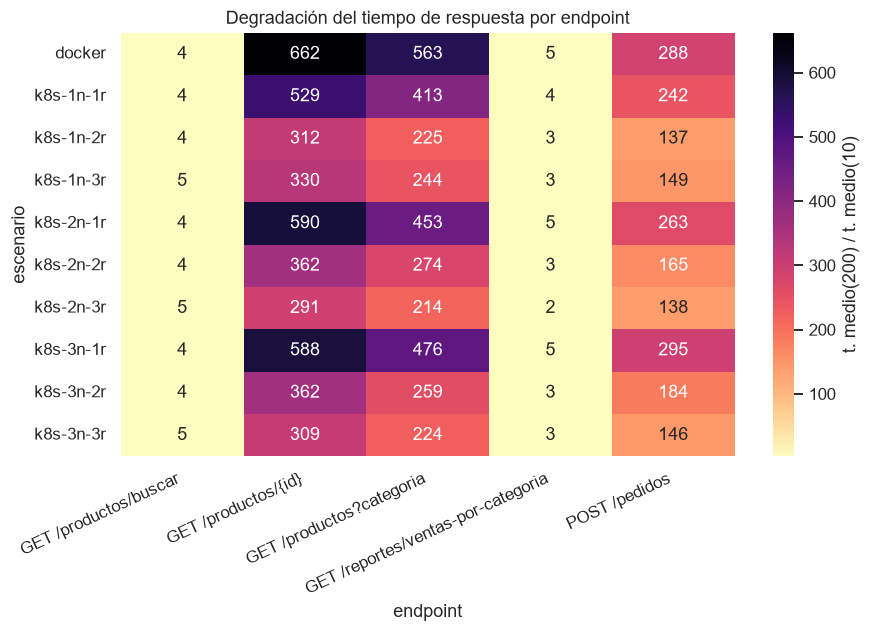

usuarios                                         10       50       100  \
escenario endpoint                                                       
docker    GET /productos/buscar               4638.0   8586.0  11971.0   
          GET /productos/{id}                   19.0   2422.0   5819.0   
          GET /productos?categoria              23.0   2444.0   5797.0   
          GET /reportes/ventas-por-categoria  4188.0   9374.0  12743.0   
          POST /pedidos                         44.0   2273.0   5661.0   
k8s-3n-3r GET /productos/buscar               4530.0  14272.0  17018.0   
          GET /productos/{id}                   20.0    404.0   2253.0   
          GET /productos?categoria              28.0    419.0   2285.0   
          GET /reportes/ventas-por-categoria  3981.0   4787.0   6504.0   
          POST /pedidos                         44.0    369.0   2292.0   

usuarios                                          200  
escenario endpoint                                     
docker    GET /productos/buscar               18888.0  
          GET /productos/{id}                 12694.0  
          GET /productos?categoria            12704.0  
          GET /reportes/ventas-por-categoria  19843.0  
          POST /pedidos                       12567.0  
k8s-3n-3r GET /productos/buscar               20856.0  
          GET /productos/{id}                  6093.0  
          GET /productos?categoria             6186.0  
          GET /reportes/ventas-por-categoria  10195.0  
          POST /pedidos                        6383.0

In [13]:
ep = res_ep.groupby(["escenario", "endpoint", "usuarios"]).rt_medio_ms.mean().reset_index()
carga_min = ep.usuarios.min()
deg = (ep[ep.usuarios == CARGA_MAX].set_index(["escenario", "endpoint"]).rt_medio_ms
       / ep[ep.usuarios == carga_min].set_index(["escenario", "endpoint"]).rt_medio_ms).unstack()
deg = deg.reindex([e for e in ORDEN if e in deg.index])
plt.figure(figsize=(9, 5))
sns.heatmap(deg, annot=True, fmt=".0f", cmap="magma_r",
            cbar_kws={"label": f"t. medio({CARGA_MAX}) / t. medio({carga_min})"})
plt.title("Degradación del tiempo de respuesta por endpoint"); plt.xticks(rotation=25, ha="right"); plt.show()
ep[ep.escenario.isin(["docker", "k8s-3n-3r"])].pivot_table(
    index=["escenario", "endpoint"], columns="usuarios", values="rt_medio_ms").round(0)

### 7.11 Validez de la medición: CPU del generador de carga

In [14]:
cpu = []
for f in RESULTS.glob("*/u*_vmstat.txt"):
    v = [l.split() for l in f.read_text().splitlines() if l.split() and l.split()[0].isdigit()]
    if len(v) > 1:
        cpu.append({"escenario": f.parent.name, "cpu_jmeter_pct": np.mean([100 - int(x[14]) for x in v[1:]])})
cpu = pd.DataFrame(cpu)
print(f"CPU media de vm-jmeter: {cpu.cpu_jmeter_pct.mean():.1f} % · máxima en una corrida: {cpu.cpu_jmeter_pct.max():.1f} %")
print("Muy por debajo del 80 %: el generador de carga nunca fue el cuello de botella.")

CPU media de vm-jmeter: 3.1 % · máxima en una corrida: 4.8 %
Muy por debajo del 80 %: el generador de carga nunca fue el cuello de botella.


## 8. Métricas internas (Prometheus)

Archivos `results/prometheus/<escenario>_u<U>_r<R>_<metrica>.csv`. Se promedia cada serie durante la corrida
(sin los primeros 30 s) con la carga máxima.

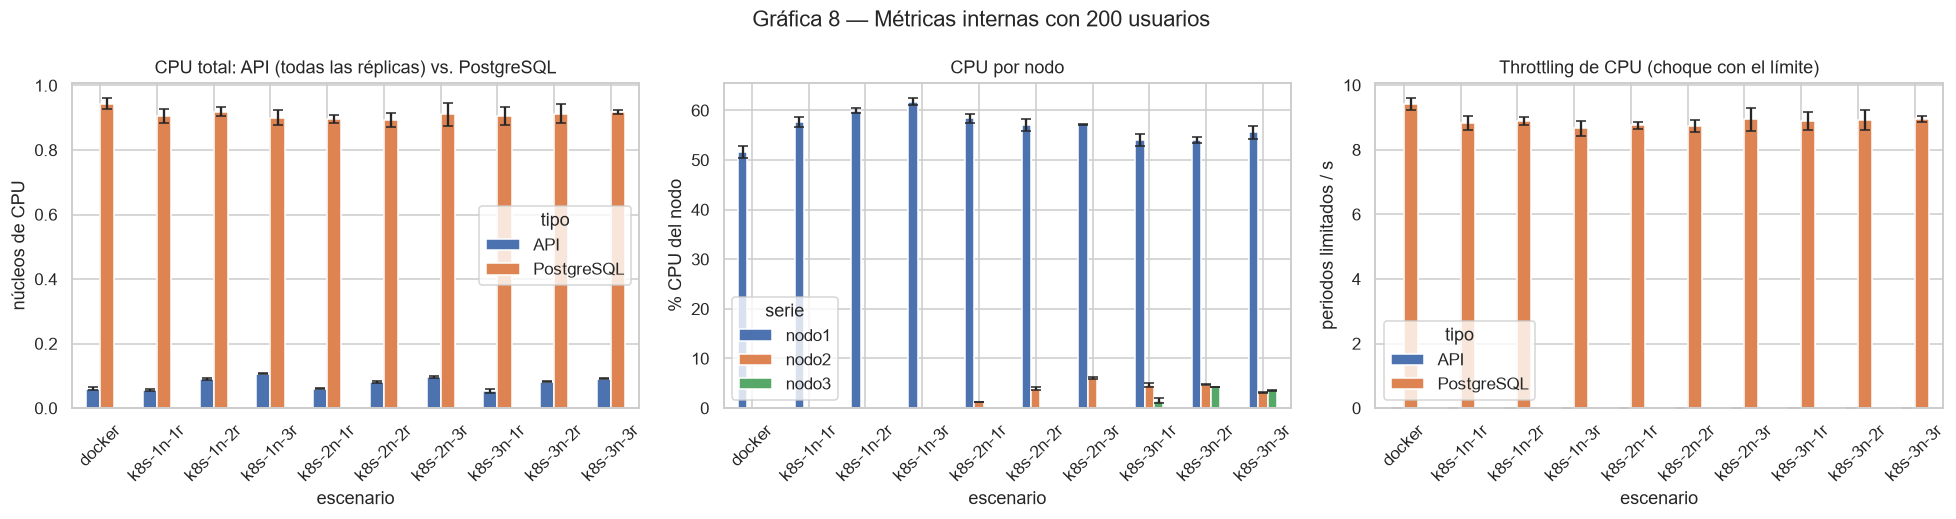

tipo,API,PostgreSQL
escenario,,
docker,0.06,0.94
k8s-1n-1r,0.06,0.91
k8s-1n-2r,0.09,0.92
k8s-1n-3r,0.11,0.90
k8s-2n-1r,0.06,0.90
k8s-2n-2r,0.08,0.89
k8s-2n-3r,0.10,0.91
k8s-3n-1r,0.05,0.91
k8s-3n-2r,0.08,0.91


In [15]:
partes = []
for f in (RESULTS / "prometheus").glob("*.csv"):
    m = re.match(r"(.+)_u(\d+)_r(\d+)_(\w+)\.csv$", f.name)
    df = pd.read_csv(f)
    if df.empty:
        continue
    df = df[df.ts >= df.ts.min() + RAMP_MS / 1000]
    g = df.groupby("serie").valor.mean().reset_index()
    g[["escenario", "usuarios", "rep", "metrica"]] = m.group(1), int(m.group(2)), int(m.group(3)), m.group(4)
    partes.append(g)
prom = pd.concat(partes, ignore_index=True)

def tipo(serie):
    s = str(serie)
    if "postgres" in s or "-db-" in s:
        return "PostgreSQL"
    if s.startswith("api") or "-api-" in s:
        return "API"
    return "otro"
NOMBRE_NODO = {"10.0.1.10:9100": "nodo1", "node-exporter:9100": "nodo1",
               "10.0.1.11:9100": "nodo2", "10.0.1.12:9100": "nodo3"}
prom["tipo"] = prom.serie.map(tipo)
es_nodo = prom.metrica == "cpu_nodo"
prom.loc[es_nodo, "serie"] = prom.loc[es_nodo, "serie"].map(NOMBRE_NODO)
prom_max = prom[prom.usuarios == CARGA_MAX]
orden_p = [e for e in ORDEN if e in set(prom_max.escenario)]

def barras(ax, por_rep, col, escala=1):
    g = por_rep.groupby(["escenario", col]).valor
    g.mean().mul(escala).unstack().reindex(orden_p).plot.bar(
        ax=ax, rot=45, capsize=3, yerr=g.std().fillna(0).mul(escala).unstack().reindex(orden_p))

def por_tipo(metrica):   # suma de las réplicas de cada tipo, por repetición
    d = prom_max[(prom_max.metrica == metrica) & (prom_max.tipo != "otro")]
    return d.groupby(["escenario", "rep", "tipo"]).valor.sum().reset_index()

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
barras(axes[0], por_tipo("cpu_pod"), "tipo"); axes[0].set_ylabel("núcleos de CPU")
axes[0].set_title("CPU total: API (todas las réplicas) vs. PostgreSQL")
barras(axes[1], prom_max[prom_max.metrica == "cpu_nodo"], "serie", escala=100)
axes[1].set_ylabel("% CPU del nodo"); axes[1].set_title("CPU por nodo")
barras(axes[2], por_tipo("throttling_pod"), "tipo")
axes[2].set_ylabel("periodos limitados / s"); axes[2].set_title("Throttling de CPU (choque con el límite)")
fig.suptitle(f"Gráfica 8 — Métricas internas con {CARGA_MAX} usuarios"); fig.tight_layout(); plt.show()

por_tipo("cpu_pod").groupby(["escenario", "tipo"]).valor.mean().unstack().reindex(orden_p).round(2)

### 8.1 Hallazgo: PostgreSQL es el cuello de botella

En **todos** los escenarios PostgreSQL usa ~0,9 núcleos (su límite es 1) y sufre *throttling* constante
(~9 periodos limitados por segundo), mientras que **todas las réplicas de la API juntas usan menos de 0,11 núcleos**.
nodo1, donde vive PostgreSQL, trabaja al 51-62 % y los demás nodos por debajo del 7 %.

### 8.2 Hallazgo: las sondas por defecto de Kubernetes tumban un servicio saturado

La primera medición de `k8s-1n-1r` usó sondas con `timeoutSeconds: 1` (valor por defecto). Bajo carga, `/health` tarda más
de 1 s porque espera a la base de datos: la *liveness probe* falló, Kubernetes **reinició el pod en plena prueba**
(`CrashLoopBackOff`, 9 reinicios) y PostgreSQL también salía del servicio. Con la *readiness* a 10 s el pod ya no se
reiniciaba, pero con 200 usuarios salía del Service y el NodePort quedaba sin destino. Se dejó readiness con 30 s de
timeout y 8 fallos, y liveness por TCP. Esas corridas se descartaron del análisis:

In [16]:
filas = []
for nombre, carpeta in [("sondas por defecto (1 s)", DESCARTADOS / "k8s-1n-1r-sondas-1s"),
                        ("readiness 10 s", DESCARTADOS / "k8s-1n-1r-readiness-10s"),
                        ("sondas finales (usadas)", RESULTS / "k8s-1n-1r")]:
    for f in carpeta.glob("u*_r*.jtl"):
        u = int(re.findall(r"u(\d+)_r", f.name)[0])
        d = pd.read_csv(f, low_memory=False, usecols=["timeStamp", "success"])
        d = d[d.timeStamp >= d.timeStamp.min() + RAMP_MS]
        filas.append({"configuración": nombre, "usuarios": u,
                      "error": 100 * (1 - (d.success.astype(str).str.lower() == "true").mean())})
(pd.DataFrame(filas).pivot_table(index="configuración", columns="usuarios", values="error")
   .reindex(["sondas por defecto (1 s)", "readiness 10 s", "sondas finales (usadas)"]).round(1)
   .rename(columns=lambda u: f"% error con {u} usuarios"))

usuarios,% error con 10 usuarios,% error con 50 usuarios,% error con 100 usuarios,% error con 200 usuarios
configuración,,,,
sondas por defecto (1 s),0.0,19.2,87.2,68.9
readiness 10 s,0.0,0.5,0.6,6.0
sondas finales (usadas),0.0,0.5,0.4,0.9


## 9. Análisis comparativo

**1. ¿El throughput crece al aumentar réplicas? ¿De forma lineal?**
Sí, pero muy lejos de lo lineal. Con 200 usuarios pasa de ~14,5 req/s (1 réplica) a ~20 (2 réplicas, speedup ≈ 1,36) y
~23 (3 réplicas, speedup ≈ 1,55); el ideal sería 2 y 3 (Gráfica 4). La API no es la que limita (usa < 0,11 núcleos):
lo que cambia con más réplicas es que hay **más conexiones simultáneas a PostgreSQL** (de 15 a 30 y 45).
**Advertencia:** ese aumento coincide con que **fallan el 70-84 % de los reportes** (sección 7.9). Cada reporte abortado
es una agregación pesada que PostgreSQL no termina, y ese tiempo queda libre para las lecturas ligeras. Parte de la
mejora es, por tanto, a costa de un endpoint degradado.

**2. ¿En qué carga se satura cada configuración?**
Con 1 réplica (y en Docker) el sistema **ya está saturado con 10 usuarios**: el throughput no pasa de ~14,5-15 req/s y el
tiempo medio crece casi en proporción a los usuarios (0,7 s → 3,4 s → 6,9 s → 13,8 s). Con 2 y 3 réplicas la meseta llega
con **50 usuarios** (~20 y ~22-23 req/s) y desde ahí solo crece el tiempo de respuesta (Gráficas 1 y 2).

**3. ¿3 réplicas en 1 nodo rinden igual que 3 réplicas en 3 nodos?**
Prácticamente sí: 22,7 vs. 23,6 req/s con 200 usuarios (+4 %). La pista de la guía (competencia por CPU dentro del nodo) no
aplica aquí porque las réplicas casi no usan CPU. Lo que sí se nota un poco es **dónde queda la API respecto a
PostgreSQL** (tabla de la sección 4): con 1 réplica, en las fases de 1 y 2 nodos el scheduler la dejó en nodo1, junto a la
BD (14,5 req/s), y en la de 3 nodos en nodo2 (15,3 req/s, +5 %); con 3 réplicas pasan de estar las 3 en nodo1 a una por
nodo (+4 %). Separar la API del nodo de la BD ayuda, pero muy poco (Gráfica 6).

**4. ¿La base de datos es el cuello de botella?**
Sí, de forma clara: PostgreSQL al ~90 % de su límite de 1 CPU con *throttling* constante, frente a menos de 0,11 núcleos
para todas las réplicas de la API (Gráfica 8). Las consultas más costosas son la búsqueda `ILIKE` (recorre los 100.000
productos) y el reporte con `GROUP BY` sobre ~600.000 items: tardan 4-5 s **incluso con 10 usuarios**.

**5. ¿Cuánto overhead añade Kubernetes frente a Docker Compose?**
Muy poco: con 1 réplica, K8s queda entre −3,5 % (10 usuarios) y −1,5 % (200 usuarios) de throughput respecto a Docker,
con tiempos de respuesta equivalentes (Gráfica 5). La diferencia está dentro del orden de la variación entre escenarios.

**6. ¿Agregar nodos ayuda si la BD sigue siendo una sola instancia?**
No de forma significativa: con las mismas réplicas, pasar de 1 a 3 nodos cambia el throughput en ≤ 5 %. En la fase de
3 nodos, nodo2 y nodo3 trabajan por debajo del 7 % de CPU: la capacidad añadida queda sin usar porque el trabajo se
acumula en la única instancia de PostgreSQL (fijada en nodo1).

**7. ¿Qué endpoint se degrada más?**
En términos relativos, las **lecturas simples** (por id, por categoría y el `POST`): pasan de ~20-45 ms con 10 usuarios a
~12,7 s con 200 en Docker (×300-600), porque esperan turno detrás de las consultas pesadas en el pool de conexiones. En
términos absolutos, la búsqueda y el reporte son los más lentos (~19-20 s con 200 usuarios). Con 3 réplicas las lecturas
simples mejoran (~6 s con 200 usuarios), la búsqueda empeora (~21 s) y el reporte "mejora" solo porque la mayoría falla.

**8. Limitante: el punto de entrada.** Todo el tráfico entra por el NodePort de nodo1. No llegó a ser el límite (nodo1
estaba al 51-62 % de CPU, casi todo por PostgreSQL), pero en un sistema sin el cuello de botella de la BD lo sería.

## 10. Conclusiones

1. **El cuello de botella del sistema es la base de datos**, no la capa de aplicación. Con una sola instancia de
   PostgreSQL limitada a 1 CPU, el throughput se estanca en ~15 req/s con 1 réplica, y ni Docker ni Kubernetes lo cambian.
2. **Kubernetes casi no añade costo** sobre el mismo hardware: con 1 réplica rinde entre 1,5 % y 3,5 % menos que Docker
   Compose, a cambio de escalado, autorreparación y reparto de carga.
3. **Escalar réplicas de una capa sin estado ayuda poco si el estado está centralizado**: 3 réplicas dan 1,55× y no 3×,
   y parte de esa mejora se debe a que el reporte pesado empieza a fallar. Escalar la API **traslada la presión a la
   base de datos** y expone en ella nuevos límites (aquí, la memoria compartida `/dev/shm`).
4. **Agregar nodos no mejora el rendimiento** cuando el recurso que limita no se replica: con 3 nodos, dos de ellos
   quedaron por debajo del 7 % de CPU.
5. **La configuración por defecto de Kubernetes puede empeorar un sistema saturado**: las sondas con 1 s de timeout
   reiniciaban la API en plena carga y llevaban los errores de < 1 % a 69-87 %. Las sondas deben medir si el proceso está
   vivo, no si está rápido.
6. **Las métricas internas fueron imprescindibles**: con JMeter solo se veía que el sistema no escalaba; Prometheus mostró
   por qué (CPU y *throttling* de PostgreSQL frente a una API casi ociosa).

## 11. Recomendaciones

- **Atacar primero la base de datos**, que es lo que limita:
  - índice trigram (`pg_trgm`) para la búsqueda `ILIKE` y una vista materializada o caché (Redis) para el reporte;
  - más CPU para PostgreSQL o **réplicas de lectura** para repartir las consultas;
  - montar un `/dev/shm` más grande (`emptyDir` con `medium: Memory` en K8s, `shm_size` en Compose) o ajustar
    `max_parallel_workers_per_gather` para que el reporte no falle con más conexiones;
  - un *pooler* como **PgBouncer** para controlar cuántas conexiones llegan a PostgreSQL al escalar la API.
- **Sondas de Kubernetes tolerantes a la saturación**: liveness simple (TCP o un endpoint que no toque la BD) y readiness
  con timeouts acordes a la latencia real bajo carga.
- **Horizontal Pod Autoscaler** solo cuando la API sea el límite: con estas métricas (API < 0,11 núcleos) no escalaría,
  y es correcto que no lo haga.
- **Ingress o balanceador externo** en lugar de depender del NodePort de un solo nodo.
- Repetir el experimento con la BD optimizada para medir el escalado real de la API y comparar con estos resultados.